# Week 5 — Volatility forecasting
Grace | RGBFS

Forecast next 20 trading days of annualized SPY realized volatility using past volatility and market-adjusted cluster features. All settings are proposed, subject to team agreement.

## 1. Configuration

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/processed').is_dir())
OUTPUT_DIR = ROOT / 'notebooks/outputs/grace_week5'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
H = 20
ANNUALIZATION = 252
RETURN_COLUMN = 'SPY_ret'
WINDOWS = [5, 20, 60]


### Configuration rationale
The forecast is made at the close of trading date $t$. SPY daily returns serve as the market proxy; the next 20 trading days represent approximately one trading month. The 5-, 20-, and 60-day trailing windows represent short-, medium-, and longer-term volatility. Annualization uses 252 trading days, with volatility expressed as a decimal (0.20 means 20%). These settings are proposed research choices, not team-mandated parameters.

## 2. Load and validate datasets

In [11]:
market = pd.read_parquet(ROOT / 'data/processed/returns_market.parquet')
clusters = pd.read_parquet(ROOT / 'data/processed/features/clusters_market_adjusted_20d.parquet')
for df in (market, clusters):
    df.index = pd.to_datetime(df.index)
    df.sort_index(inplace=True)
    assert df.index.is_unique, 'Duplicate dates found'
    print(df.shape, df.index.min(), df.index.max())
    display(df.head())
    display(df.isna().sum())


(5490, 4) 2005-01-03 00:00:00 2026-10-28 00:00:00


C:\Users\dayan\AppData\Local\Temp\ipykernel_6772\3325974154.py:5: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_index(inplace=True)


,^GSPC_ret,SPY_ret,ew_member_ret,n_returns
Date,,,,
2005-01-03,NaN,NaN,NaN,0
2005-01-04,-0.011671,-0.012220,-0.013482,263
2005-01-05,-0.003628,-0.006900,-0.006309,263
2005-01-06,0.003506,0.005084,0.003625,263
2005-01-07,-0.001431,-0.001433,-0.002553,263


^GSPC_ret        1
SPY_ret          1
ew_member_ret    1
n_returns        0
dtype: int64

(271, 9) 2005-04-27 00:00:00 2026-10-14 00:00:00


C:\Users\dayan\AppData\Local\Temp\ipykernel_6772\3325974154.py:5: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_index(inplace=True)


,n_stocks,n_nodes,n_edges,density,n_communities,modularity,largest_share,sector_ari,stability
date,,,,,,,,,
2005-04-27,263,262,1723,0.050393,7,0.565147,0.217557,0.209351,NaN
2005-05-25,263,263,1723,0.050010,6,0.581243,0.311787,0.270707,0.385897
2005-06-23,264,264,1736,0.050006,7,0.566687,0.238636,0.222054,0.285635
2005-07-22,264,264,1736,0.050006,8,0.553370,0.200758,0.214440,0.207906
2005-08-19,264,264,1736,0.050006,7,0.572407,0.242424,0.183262,0.300534


n_stocks         0
n_nodes          0
n_edges          0
density          0
n_communities    0
modularity       0
largest_share    0
sector_ari       0
stability        1
dtype: int64

### Interpretation — data availability and quality
The market-return dataset contains 5,490 rows and four columns from January 3, 2005 to October 28, 2026. The three return columns each contain one missing value, on the initial date. SPY_ret is the selected market proxy. The cluster dataset contains 271 snapshots and nine features from April 27, 2005 to October 14, 2026. Only stability has a missing value (the first snapshot). Both date indexes passed the uniqueness check. The pandas warning concerns future deprecation of `sort_index(inplace=True)` and did not prevent execution. The notebook does not independently establish the provenance or point-in-time construction of these data.

## 3. Target and historical volatility
At the close of date t, forecast the annualized root mean squared daily return over t+1 through t+20. Missing returns are not filled or removed from the trading calendar. Historical windows include date t.

,vol_5,vol_20,vol_60,target,target_end
count,5485.000000,5470.000000,5430.000000,5470.000000,5470
mean,0.147099,0.155126,0.161540,0.155126,2015-12-13 00:16:03.510000
min,0.013130,0.032824,0.051108,0.032824,2005-02-01 00:00:00
25%,0.077394,0.093541,0.108657,0.093541,2010-07-08 06:00:00
50%,0.118451,0.127492,0.130210,0.127492,2015-12-10 12:00:00
75%,0.177965,0.179901,0.182037,0.179901,2021-05-18 18:00:00
max,1.355561,0.939842,0.756325,0.939842,2026-10-28 00:00:00
std,0.118295,0.107867,0.098982,0.107867,NaN


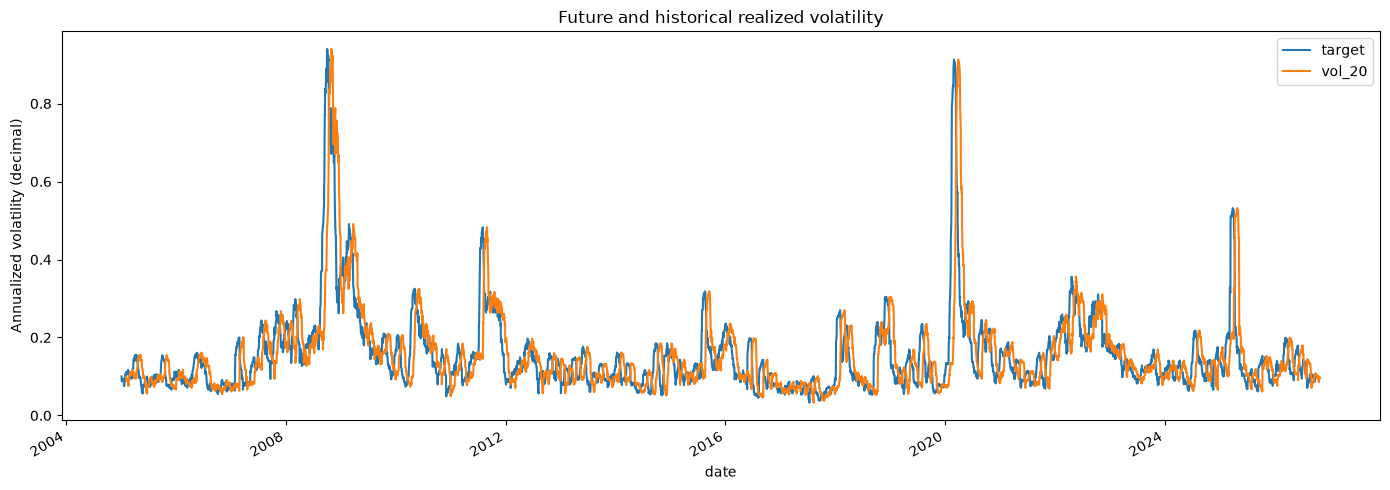

In [12]:
r = pd.to_numeric(market[RETURN_COLUMN], errors='coerce').replace([np.inf, -np.inf], np.nan)
data = pd.DataFrame(index=r.index)
data.index.name = 'date'
for w in WINDOWS:
    data[f'vol_{w}'] = np.sqrt(ANNUALIZATION * r.pow(2).rolling(w, min_periods=w).mean())
data['target'] = np.sqrt(ANNUALIZATION * r.pow(2).rolling(H, min_periods=H).mean().shift(-H))
data['target_end'] = pd.Series(r.index, index=r.index).shift(-H)
display(data.describe())
data[['target','vol_20']].plot(figsize=(14,5), title='Future and historical realized volatility')
plt.ylabel('Annualized volatility (decimal)')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'realized_volatility.png', dpi=150); plt.show()


### Interpretation — realized volatility target
The annualized future realized volatility is defined by

$$y_t=\sqrt{\frac{252}{20}\sum_{i=1}^{20}r_{t+i}^2}.$$

Historical predictors use $\sqrt{(252/w)\sum_{i=0}^{w-1}r_{t-i}^2}$ for $w=5,20,60$. The forward shift ensures that the target excludes the return on the forecast date. The historical features include that date's return, so this is an end-of-day forecast. Missing returns are not imputed.

The descriptive output reports 5,470 available target values before complete-case filtering. Mean target volatility is 15.51%, median 12.75%, minimum 3.28%, and maximum 93.98%. The 60-day predictor has 5,430 available values. The chart illustrates the time variation of volatility and the relationship between trailing and future volatility; future target values are labels, not information available to the model at the forecast date. The shorter window is more responsive to sudden return movements, while the longer window smooths them.

## 4. Integrate cluster features
Use backward as-of matching, never a future cluster observation. A cluster snapshot is assumed available at its dated close; confirm this with the team, including whether sector labels or stability use future information. Exclude sector ARI from predictors by default because historical classification provenance is uncertain. Do not carry snapshots beyond 40 calendar days.

In [13]:
cluster_cols = ['n_stocks','n_nodes','n_edges','density','n_communities','modularity','largest_share','stability']
cl = clusters[cluster_cols].copy()
cl.index.name = 'cluster_date'
joined = pd.merge_asof(data.reset_index(), cl.reset_index(), left_on='date', right_on='cluster_date', direction='backward', tolerance=pd.Timedelta(days=40)).set_index('date')
assert (joined.loc[joined.cluster_date.notna(), 'cluster_date'] <= joined.index[joined.cluster_date.notna()]).all()
base_cols = [f'vol_{w}' for w in WINDOWS]
full_cols = base_cols + cluster_cols
sample = joined.dropna(subset=full_cols + ['target','target_end']).copy()
print('Common eligible observations:',len(sample))
display(sample.head())


Common eligible observations: 5371


,vol_5,vol_20,vol_60,target,target_end,cluster_date,n_stocks,n_nodes,n_edges,density,n_communities,modularity,largest_share,stability
date,,,,,,,,,,,,,,
2005-05-25,0.053354,0.114519,0.121049,0.075013,2005-06-23,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
2005-05-26,0.058324,0.107218,0.121542,0.077098,2005-06-24,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
2005-05-27,0.058644,0.095968,0.121587,0.077039,2005-06-27,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
2005-05-31,0.062914,0.096586,0.119599,0.079410,2005-06-28,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
2005-06-01,0.085765,0.101045,0.120868,0.074007,2005-06-29,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897


### Interpretation — contribution of clustering features
The backward as-of join selects the latest cluster snapshot dated on or before each forecast date, with a maximum age of 40 calendar days. This avoids matching a forecast date to a later snapshot, conditional on the snapshot itself having been constructed using only information available at that time. The first eligible forecast is May 25, 2005. After requiring all predictors and the target to be available, 5,371 common observations remain.

| Feature | Role in forecasting |
|---|---|
| `n_stocks` | Eligible stock universe size |
| `n_nodes` | Network participation |
| `n_edges` | Number of connections |
| `density` | Relative connectivity |
| `n_communities` | Number of detected groups |
| `modularity` | Strength of community structure |
| `largest_share` | Concentration in the largest community |
| `stability` | Persistence of community structure, subject to verifying its construction |

Sector ARI is excluded because historical sector provenance is uncertain. The enhanced model uses the eight listed features plus the same three volatility predictors as the HAR-style baseline. The common sample ensures a fair comparison on identical dates. Periodic snapshots are reused across daily rows; this does not create independent daily cluster measurements.

## 5. Chronological split with purging
Use the same eligible dates for all models. Remove training and validation rows whose future target windows reach the next split. Validation is diagnostic; test is held out.

In [14]:
n_rows = len(sample)
a, b = int(.70*n_rows), int(.85*n_rows)
assert 0 < a < b < n_rows
val_start, test_start = sample.index[a], sample.index[b]
train = sample.iloc[:a].loc[lambda d: d.target_end < val_start]
val = sample.iloc[a:b].loc[lambda d: d.target_end < test_start]
test = sample.iloc[b:]
for name, df in [('train',train),('validation',val),('test',test)]:
    assert len(df)>0
    print(name, len(df), df.index.min(), df.index.max())
assert train.target_end.max() < val.index.min()
assert val.target_end.max() < test.index.min()


train 3739 2005-05-25 00:00:00 2020-04-01 00:00:00
validation 786 2020-05-01 00:00:00 2023-06-14 00:00:00
test 806 2023-07-17 00:00:00 2026-09-30 00:00:00


### Interpretation — chronological evaluation and leakage control
| Split | Observations | First forecast date | Last forecast date |
|---|---:|---|---|
| Training | 3,739 | 2005-05-25 | 2020-04-01 |
| Validation | 786 | 2020-05-01 | 2023-06-14 |
| Test | 806 | 2023-07-17 | 2026-09-30 |

The approximate 70/15/15 chronological split removes 40 observations in total at the boundaries. The assertions verify that the training targets end before validation begins and validation targets end before testing begins. This prevents target-window overlap across these split boundaries. Within each split, adjacent 20-day labels still overlap. No random shuffling is used. Both regression models are fitted on training data only; validation and test observations are not used for fitting.

## 6. Baseline and enhanced models
Persistence uses trailing 20-day volatility. The HAR-style linear model uses 5, 20 and 60-day volatility. The enhanced linear model adds cluster features. Negative predictions are clipped at zero for both regressions. Fit on training only; no test-based tuning.

In [15]:
models = {'HAR_style': (LinearRegression(),base_cols), 'Volatility_plus_clusters': (LinearRegression(),full_cols)}
for model, cols in models.values():
    model.fit(train[cols], train.target)
rows=[]; predictions=[]
for split, df in [('validation',val),('test',test)]:
    pred = pd.DataFrame({'actual':df.target,'Persistence':df.vol_20},index=df.index)
    for name,(model,cols) in models.items():
        pred[name]=np.maximum(0,model.predict(df[cols]))
    for name in ['Persistence',*models]:
        rows.append(dict(split=split, model=name, MAE=mean_absolute_error(pred.actual,pred[name]), RMSE=np.sqrt(mean_squared_error(pred.actual,pred[name])), R2=r2_score(pred.actual,pred[name]), n=len(df)))
    pred['split']=split
    predictions.append(pred)
performance=pd.DataFrame(rows)
predictions=pd.concat(predictions)
display(performance)


,split,model,MAE,RMSE,R2,n
0,validation,Persistence,0.046640,0.059306,0.143095,786
1,validation,HAR_style,0.043588,0.054243,0.283167,786
2,validation,Volatility_plus_clusters,0.046393,0.056699,0.216797,786
3,test,Persistence,0.049287,0.081635,-0.380014,806
4,test,HAR_style,0.043533,0.070287,-0.022990,806
5,test,Volatility_plus_clusters,0.055302,0.077053,-0.229446,806


### Interpretation — baseline and enhanced model performance
Persistence forecasts the next 20-day volatility using the trailing 20-day value. The HAR-style regression combines the three trailing volatility windows. The enhanced regression adds the eight cluster features. Both regressions clip negative predictions to zero. MAE measures typical absolute error, RMSE gives greater weight to large errors, and R² compares squared error to a constant equal to the evaluation-set mean.

| Split | Model | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| Validation | Persistence | 0.046640 | 0.059306 | 0.143095 |
| Validation | HAR-style | 0.043588 | 0.054243 | 0.283167 |
| Validation | Volatility + clusters | 0.046393 | 0.056699 | 0.216797 |
| Test | Persistence | 0.049287 | 0.081635 | -0.380014 |
| Test | HAR-style | 0.043533 | 0.070287 | -0.022990 |
| Test | Volatility + clusters | 0.055302 | 0.077053 | -0.229446 |

HAR-style ranks first on all three metrics in both splits. Its test MAE corresponds to approximately 4.35 annualized volatility percentage points. Its test RMSE is approximately 13.90% lower than persistence. Adding cluster features increases RMSE approximately 9.63% relative to HAR-style and increases MAE. All test R² values are negative, indicating worse squared-error performance than the retrospective test-set mean benchmark; that mean is not itself an available real-time forecast. The results do not establish that cluster features are generally useless, only that this linear specification does not improve upon HAR-style in this experiment.

## 7. Visualize test performance

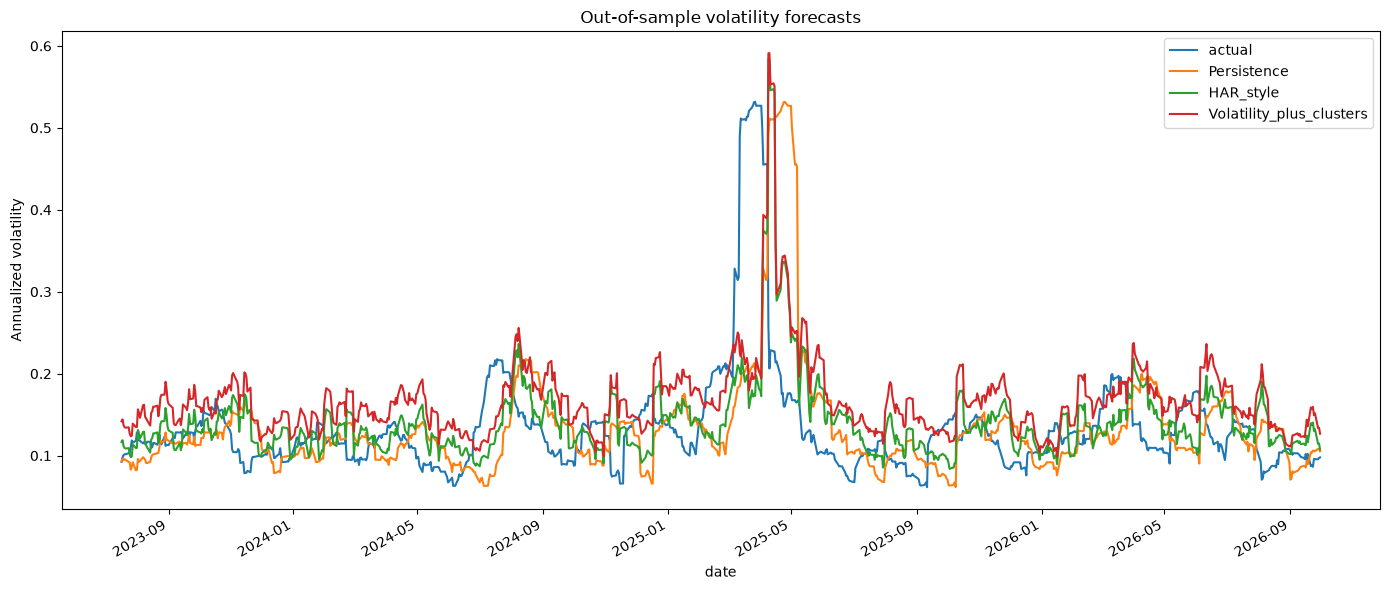

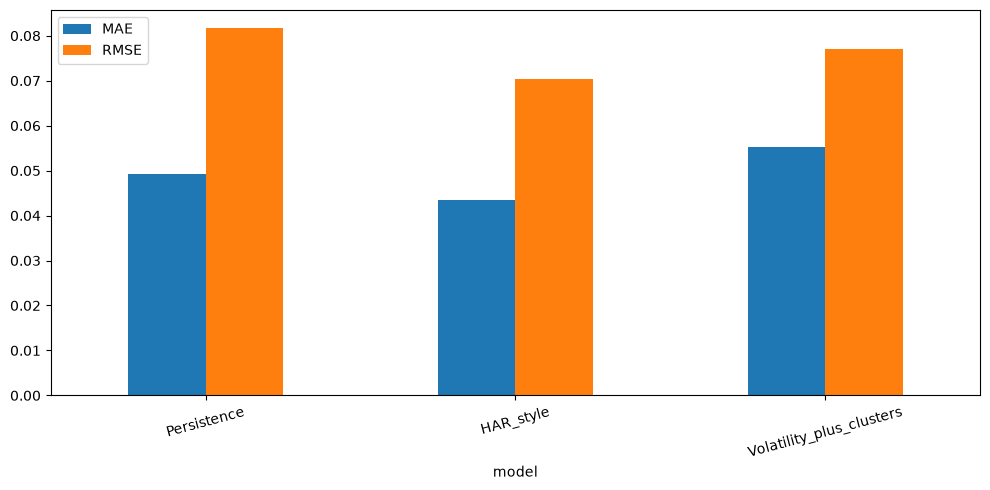

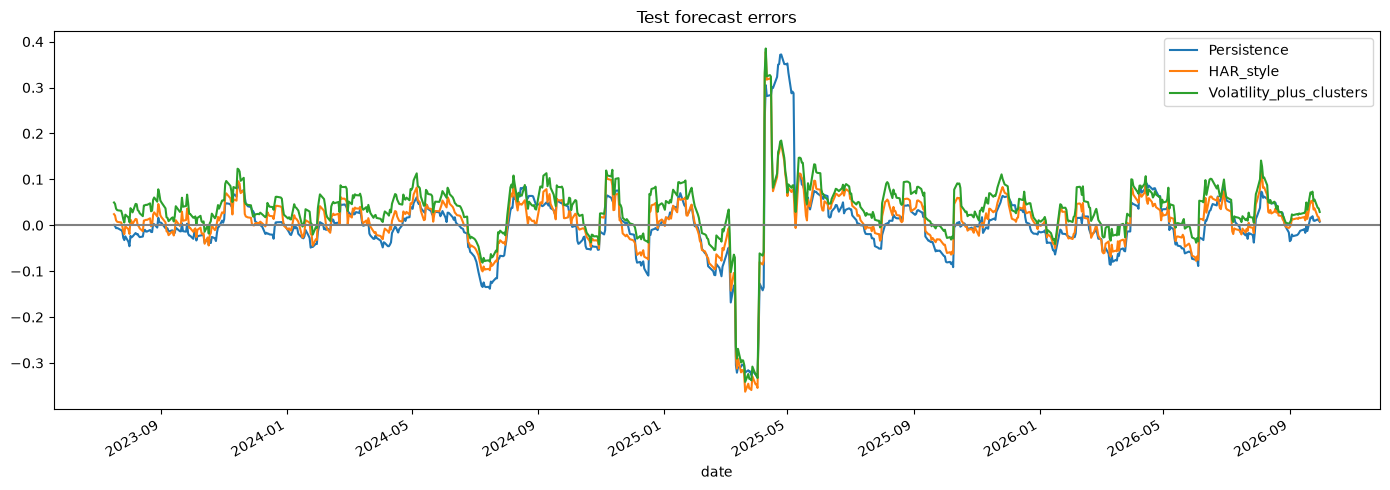

In [16]:
p=predictions.loc[predictions.split.eq('test')].drop(columns='split')
p.plot(figsize=(14,6), title='Out-of-sample volatility forecasts')
plt.ylabel('Annualized volatility'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'actual_vs_predicted_volatility.png',dpi=150); plt.show()
performance.query("split == 'test'").set_index('model')[['MAE','RMSE']].plot.bar(figsize=(10,5),rot=15)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'model_performance_comparison.png',dpi=150); plt.show()
p.drop(columns='actual').sub(p.actual,axis=0).plot(figsize=(14,5),title='Test forecast errors')
plt.axhline(0,color='gray'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'forecast_errors.png',dpi=150); plt.show()


### Interpretation — forecasting visualizations
**Actual versus predicted volatility.** The first plot compares the three forecast series against realized future volatility over the 806 common test dates. Forecasts are aligned by forecast origin rather than the target end date. This permits inspection of timing, peak tracking, and differences in responsiveness without mistaking the future target for an input.

**Model performance comparison.** The second plot confirms that HAR-style has the lowest test MAE and RMSE. The enhanced model has worse MAE than persistence but better RMSE, illustrating why both error measures are useful.

**Forecast errors.** The third plot defines error as predicted minus actual volatility. Positive errors indicate overprediction; negative errors indicate underprediction. Large deviations contribute disproportionately to RMSE. The chart is diagnostic and does not establish statistical independence or significance.

## 8. Export deliverables

In [17]:
sample.to_csv(OUTPUT_DIR/'forecasting_dataset.csv')
data[['target','target_end']].to_csv(OUTPUT_DIR/'volatility_target.csv')
joined[['cluster_date',*cluster_cols]].to_csv(OUTPUT_DIR/'cluster_forecasting_features.csv')
predictions[['actual','Persistence','HAR_style','split']].to_csv(OUTPUT_DIR/'baseline_predictions.csv')
predictions[['actual','Volatility_plus_clusters','split']].to_csv(OUTPUT_DIR/'enhanced_model_predictions.csv')
performance.to_csv(OUTPUT_DIR/'model_performance.csv',index=False)
print('Saved:', OUTPUT_DIR)
for f in sorted(OUTPUT_DIR.iterdir()): print(f.name)


Saved: c:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week5
actual_vs_predicted_volatility.png
baseline_predictions.csv
cluster_forecasting_features.csv
enhanced_model_predictions.csv
forecast_errors.png
forecasting_dataset.csv
model_performance.csv
model_performance_comparison.png
realized_volatility.png
volatility_target.csv


### Interpretation — reproducible deliverables
The execution output lists all ten expected files in `notebooks/outputs/grace_week5/`. The CSV files provide the target and its end date, common modeling sample, aligned cluster predictors, baseline and enhanced predictions, and model metrics. The four PNG files document the volatility series, test forecasts, performance comparison, and errors. The target and modeling tables contain future outcomes for supervised learning; teammates must not use these outcomes as predictors and should retain chronological purging when extending the experiment.

## 9. Interpretation and limitations
Lower MAE and RMSE indicate better accuracy. Compare the enhanced model with the HAR-style baseline on identical test dates. Overlapping 20-day targets imply dependent errors, so metric differences do not establish statistical significance. Cluster snapshot availability and point-in-time feature construction must be confirmed. The dataset is not independently verified here.

In [18]:
t = performance.query("split == 'test'").set_index('model')
base = t.loc['HAR_style','RMSE']; enhanced = t.loc['Volatility_plus_clusters','RMSE']
print('HAR-style test RMSE:',base)
print('Enhanced test RMSE:',enhanced)
if base > 0:
    print(f'RMSE improvement: {100*(base-enhanced)/base:.2f}%')
print('Lowest test RMSE:',t.RMSE.idxmin())


HAR-style test RMSE: 0.0702865305528756
Enhanced test RMSE: 0.07705328803083462
RMSE improvement: -9.63%
Lowest test RMSE: HAR_style


### Limitations and next steps
- The experiment uses one market proxy, one 20-trading-day horizon, and a single chronological split. Results may differ across other horizons or periods.
- The cluster availability assumption (dated close) and stability calculation require confirmation with the team. Backward alignment alone does not prove the underlying features are free of look-ahead bias.
- The periodic cluster features may be stale relative to daily volatility. Redundant predictors, changing market conditions, or nonlinear relationships could explain the lack of improvement; these are hypotheses, not demonstrated causes.
- Overlapping labels produce dependent forecast errors. The observed metric differences are descriptive, not a statistical significance test. Future work could use walk-forward evaluation, horizon-aware uncertainty estimates, regularization, and feature selection, with model choices made without consulting the test set.
- The source notebook was executed by the project member; this edited version preserves those outputs but has not been independently rerun against the underlying Parquet files. Numerical interpretations describe this recorded run and should be updated if the inputs or settings change.

## 10. Final conclusion
This Week 5 analysis defines future annualized SPY realized volatility over the next 20 trading days, establishes a persistence benchmark and a HAR-style regression using only past volatility, and contributes eight market-adjusted clustering features to an enhanced model. All three assigned technical tasks are addressed.

The HAR-style baseline achieved the best validation and test performance. Its test MAE was 0.043533 and RMSE was 0.070287, approximately 13.90% lower in RMSE than persistence. The enhanced model recorded a test RMSE of 0.077053, an increase of approximately 9.63% relative to HAR-style. Thus, adding clustering features did not improve the selected baseline in this experiment. Negative test R² values demonstrate the difficulty of out-of-sample volatility forecasting under the current specifications.

The recommended reference model for subsequent team experiments is the HAR-style volatility-only baseline, with the persistence forecast retained as a simple benchmark. The aligned cluster feature table remains a useful contribution for future model development. The team should verify point-in-time feature availability before treating the results as a leakage-free predictive evaluation.

**Week 5 deliverables:** target definition and forecast horizon; volatility-only baseline models and evaluation; aligned cluster features and enhanced-model comparison; exported tables and charts.